In [5]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Lasso

Data collection and Processing

In [6]:
df = pd.read_csv("car_data.csv")

In [7]:
df.head()

,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


In [8]:
#checking number rows and colm
df.shape

(301, 9)

In [9]:
#missing values in there
df.isnull().sum()

,0
Car_Name,0
Year,0
Selling_Price,0
Present_Price,0
Kms_Driven,0
Fuel_Type,0
Seller_Type,0
Transmission,0
Owner,0


In [14]:
#checking the discributews categorical data
print(df.Fuel_Type.value_counts())
print(df.Seller_Type.value_counts())
print(df.Transmission.value_counts())

Fuel_Type
Petrol    239
Diesel     60
CNG         2
Name: count, dtype: int64
Seller_Type
Dealer        195
Individual    106
Name: count, dtype: int64
Transmission
Manual       261
Automatic     40
Name: count, dtype: int64


Encoding the categorical data

In [16]:
#encoding
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

df["Fuel_Type"] = le.fit_transform(df["Fuel_Type"])
df["Seller_Type"] = le.fit_transform(df["Seller_Type"])
df["Transmission"] = le.fit_transform(df["Transmission"])

df.head()

,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,2,0,1,0
1,sx4,2013,4.75,9.54,43000,1,0,1,0
2,ciaz,2017,7.25,9.85,6900,2,0,1,0
3,wagon r,2011,2.85,4.15,5200,2,0,1,0
4,swift,2014,4.60,6.87,42450,1,0,1,0


Splitting the data into Training data and test data

In [18]:
X = df.drop(["Car_Name",'Selling_Price'],axis=1)
y=df['Selling_Price']

In [22]:
X_train,X_test , y_train , y_test = train_test_split(
    X,y,test_size=0.2,random_state=2
)

In [23]:
#model training
model = LinearRegression()
model.fit(X_train,y_train)



LinearRegression()

In [25]:
y_test_pred = model.predict(X_test)
y_train_pred = model.predict(X_train)

In [26]:
print("r2 test :",r2_score(y_test,y_test_pred))
print("r2 train :",r2_score(y_train,y_train_pred))

r2 test : 0.8401532365377663
r2 train : 0.883816919370979


Visualization actual price and selling price

Text(0.5, 1.0, 'actual price vs predicted price')

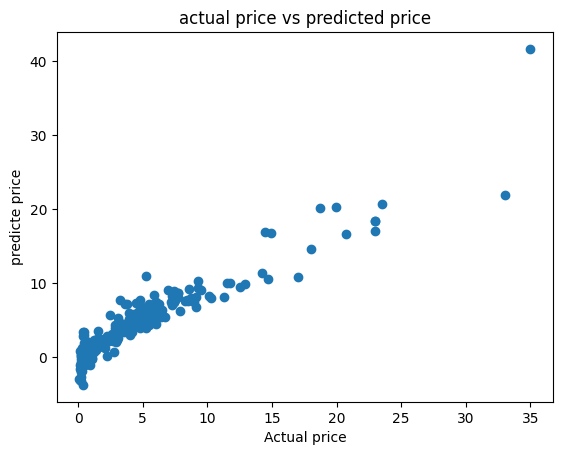

In [29]:
plt.scatter(y_train , y_train_pred)
plt.xlabel("Actual price")
plt.ylabel("predicte price")
plt.title("actual price vs predicted price")

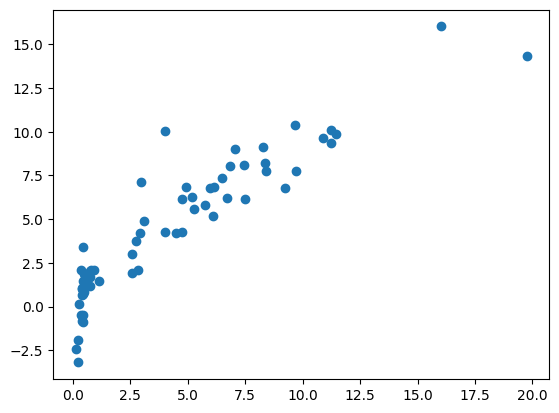

In [30]:
plt.scatter(y_test , y_test_pred)

Lasso Regresssion

In [32]:
lasso_model = Lasso()
lasso_model.fit(X_train,y_train)

Lasso()

In [34]:
y_pred = lasso_model.predict(X_test)
print("r2 test :",r2_score(y_test,y_test))


r2 test : 1.0


Text(0.5, 1.0, 'actual price vs predicted price')

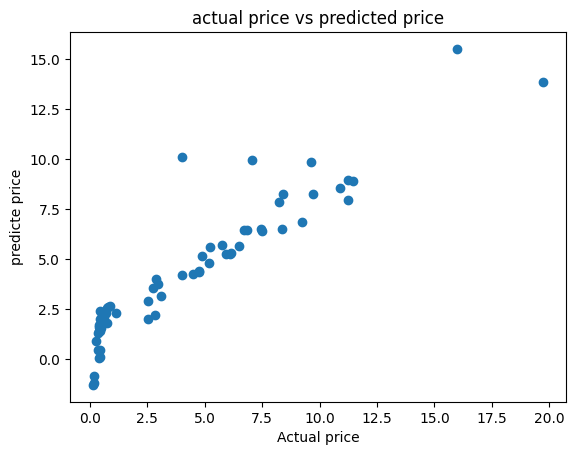

In [36]:
plt.scatter(y_test ,y_pred)
plt.xlabel("Actual price")
plt.ylabel("predicte price")
plt.title("actual price vs predicted price")